# Numerical Optimization of gut-immune interactions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from math import erf
import numba as nb
import multiprocessing as mp
from tqdm import tqdm
from joblib import Parallel, delayed
import os
from sklearn.feature_selection import mutual_info_classif
import time

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

In [2]:
# Define model parameters
nr, ng, nb = 50, 50, 50 # (receptors, microbes, resources)

F = np.random.uniform(size=(ng,nr)) # cross-reactivity: F_i,r = f_r,i
A = np.random.uniform(low = -0.1, high = 0.1, size = (ng,ng)) # species competition matrix
A[np.arange(0,ng),np.arange(0,ng)] = -1

b = np.random.uniform(size = nb) # resource abundance
C = 5*np.random.uniform(size=(ng,nb)) # resource utilization matrix
D0 = np.random.uniform(size=(nb,ng)) # resource benefit matrix
mu = np.random.uniform(size = ng) # rates of breaching gut epithelium
Lam = 1 # strength of immune pressure
gam_min, gam_max = 0,1
# Define functions
def h(gam):
    return gam

def lam(P, gam):
    return Lam*h(gam)*F.dot(P)

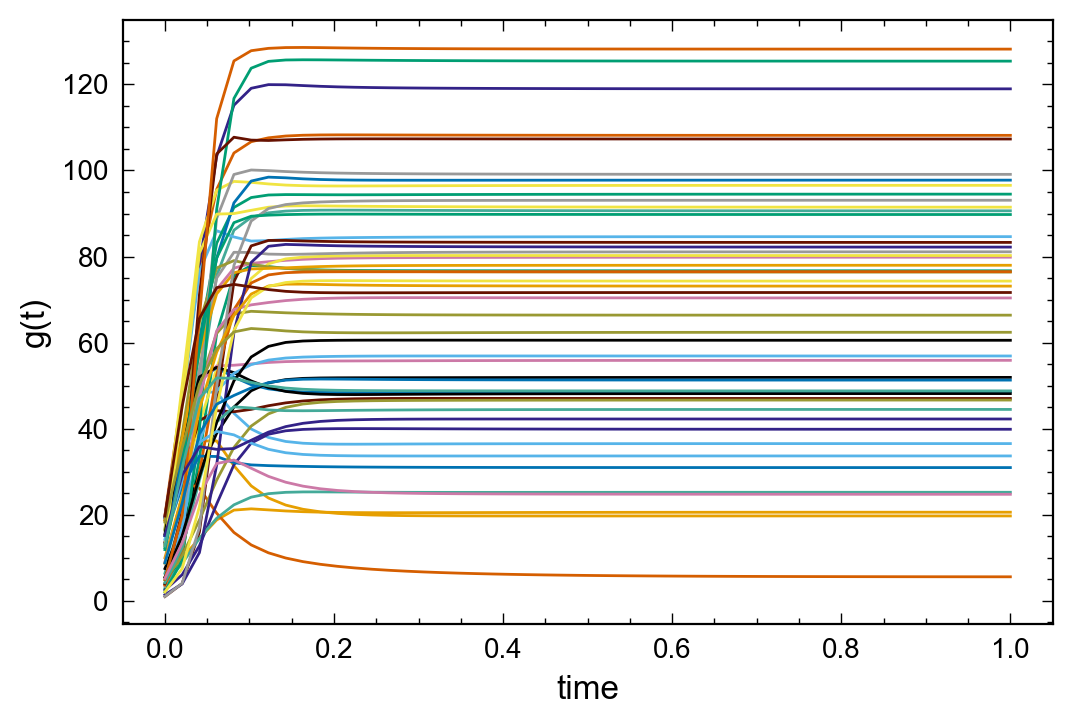

In [4]:
# Simulate microbe dynamics
from scipy.integrate import odeint

P0 = np.random.dirichlet(np.ones(nr))
gam0 = 0.9

# function that returns dx/dt = A x 
def model(g,t):
    dgdt = (-lam(P0,gam0) + C.dot(b) + A.dot(g)).dot(np.diag(g))
    return list(dgdt.ravel())

# initial condition
g0 = 20*np.random.rand(ng)

# time points
t = np.linspace(0,1)

# solve ODE
g = odeint(model,list(g0),t)

# plot results
plt.plot(t,g)
plt.xlabel('time')
plt.ylabel('g(t)')
plt.show()

In [25]:
# Define parameters
beta = 1.00

# Define cost function
def g_ss(P,gam):
    return np.linalg.solve(A, lam(P, gam) - C.dot(b))

def B(P,gam):
    return b.T.dot(D0.dot(g_ss(P,gam)))

def objective(pg):
    P, gam = pg[:-1], pg[-1]
    
    cost = (1-h(gam)*F.dot(P)).T.dot(g_ss(P,gam)*mu) - beta*B(P,gam)
    grad_P = (-gam*np.diag(mu).dot(F)).T.dot(np.linalg.solve(A, Lam*gam*F.dot(P)-C.dot(b))) \
            + (Lam*gam*F).T.dot(np.linalg.solve(A.T, mu - gam*np.diag(mu).dot(F.dot(P)) - beta*b.T.dot(D0)))
    grad_gam = (-np.diag(mu).dot(F.dot(P))).T.dot(np.linalg.solve(A, Lam*gam*F.dot(P)-C.dot(b))) \
            + (Lam*F.dot(P)).T.dot(np.linalg.solve(A.T, mu - gam*np.diag(mu).dot(F.dot(P)) - beta*b.T.dot(D0)))
    
    return cost, np.append(grad_P,grad_gam)

In [26]:
objective(np.append(P0,gam0))
#B(P0,gam0)

(-41979.843220824296,
 array([-497.68196502, -353.38356048, -407.94760049, -415.48161229,
        -412.2655904 , -481.40457626, -297.73899788, -437.99590899,
        -479.44170037, -497.647629  , -441.72420692, -502.95786936,
        -458.26467429, -363.78901852, -451.48306538, -446.80725404,
        -422.77963183, -436.43111252, -469.38964998, -472.96238872,
        -427.58723746, -381.63811362, -406.02491554, -431.99033929,
        -380.20389697, -461.97723285, -344.37802413, -512.25386923,
        -423.86044623, -356.40582011, -466.12192444, -463.85120195,
        -420.89858568, -410.35563041, -450.4440095 , -468.01571531,
        -524.91531539, -425.51009929, -493.81754027, -422.89162051,
        -461.89973847, -393.12518037, -460.12846645, -453.07044768,
        -487.93880262, -466.5926254 , -407.31999651, -411.22791716,
        -441.21292847, -487.97983259, -491.56790715]))

In [27]:
# Implement proximal gradient optimization for repertoire: https://pypi.org/project/pyproximal/
def project(pg, mask=None):
    """ Take a vector pg (with possible nonnegative entries and non-normalized)
        and project it onto the unit simplex. Take value gamma and project it onto an interval
        mask:   do not project these entries
                project remaining entries onto lower dimensional simplex
    """
    x, z = pg[:-1], pg[-1]
    
    if mask is not None:
        mask = np.asarray(mask)
        xsorted = np.sort(x[~mask])[::-1]
        # remaining entries need to sum up to 1 - sum x[mask]
        sum_ = 1.0 - np.sum(x[mask])
    else:
        xsorted = np.sort(x)[::-1]
        # entries need to sum up to 1 (unit simplex)
        sum_ = 1.0
    lambda_a = (np.cumsum(xsorted) - sum_) / np.arange(1.0, len(xsorted)+1.0)
    for i in np.arange(len(lambda_a)-1):
        if lambda_a[i] >= xsorted[i+1]:
            astar = i
            break
    else:
        astar = -1
    p = np.maximum(x-lambda_a[astar],  0)
    if mask is not None:
        p[mask] = x[mask]
    # project gam
    g = np.maximum(gam_min, np.minimum(z, gam_max))
    
    return np.append(p, g)

def minimize(objective, pg0,
             nboundupdate=100,
             reltol=1e-4, abstol=0.0, maxiters=1e7,
             algo='fast',
             show_progress=False,
             callback=None,
             full_return=False,
             mask=None):
    """
    minimize     objective(P_r)
    subject to   0.0 <= P_r
                 sum(P_r) = 1
    parameters
    ----------
    objective : function returning cost, gradient
    pg0 : starting guess for receptor Pr and tolerance gam
    nboundupdate : number of iteration between lower bound updates
    reltol, abstol, maxiters: numerical parameter
    algo: fast or normal algorithm
    show_progress: print status information during the run
    full_return: also return dict with information about optimization
    mask: Boolean array with directions along which not to optimize
    output
    ------
    optimal solution
    """

    if mask is not None:
        mask = np.asarray(mask)

        def mobjective(x):
            f, grad = objective(x)
            if grad is not None:
                grad[mask] = 0.0
            return f, grad
        mobjective = mobjective
        mproject = lambda pg: project(pg, mask)
    else:
        mobjective = objective
        mproject = project
    # initialize p and g from function input
    pg = mproject(np.asarray(pg0))
    # counting variable for number of iterations
    k = 0
    # lower bound for the cost function
    low = -beta*B(pg[:-1],pg[-1]) #0.0

    # setup for accelerated algorithm
    if algo == 'fast':
        y = pg
        f, grad = mobjective(pg)
        # starting guess for gradient scaling parameter 1 / | nabla f |
        s = 1.0 / np.linalg.norm(grad)
        # refine by backtracking search
        while True:
            y_new = mproject((y - s * grad))
            # abs important as values close to machine precision
            # might become negative in fft convolution screwing
            # up cost calculations
            f_new, grad_new = mobjective(y_new)
            if f_new < f + np.dot(y_new - y, grad.T) + \
                    0.5 * np.linalg.norm(y_new - y)**2 / s:
                break
            s *= 0.8
        # reduce s by some factor as optimal s might become smaller during
        # the course of optimization
        s /= 3.0

    told = time.time()
    while k < maxiters:
        k += 1
        f, grad = mobjective(pg)

        # update lower bound on cost function
        # initialize at beginning (k=1) and then every nboundupdateth iteration
        if (k % nboundupdate == 0) or (k == 1):
            if mask is not None:
                i = np.argmin(grad[~mask])
                low = max((low, f - np.sum(pg * grad) + grad[~mask][i]))
            else:
                i = np.argmin(grad)
                low = max((low, f - np.sum(pg * grad) + grad[i]))
            gap = f - low
            if callback:
                callback(f, pg)
            if show_progress:
                print('%g: f %e, gap %e, relgap %e' % (k, f, gap, np.abs(gap/low) if low != 0 else np.inf))
            if ((low != 0 and np.abs(gap/low) < reltol) or np.abs(gap) < abstol):
                if show_progress:
                    print( 'stopping criterion reached')
                break

        if algo == 'fast':
            f, grad = mobjective(y)
            pg, pgold = mproject(y - s * grad), pg
            y = pg + k/(k+3.0) * (pg - pgold)
        else:
            # generate feasible direction by projection
            s = 0.1
            d = mproject(pg - s * grad) - pg
            # Backtracking line search
            deriv = np.dot(grad.T, d)
            alpha = 0.1
            # in (0, 0.5)
            p1 = 0.2
            # in (0, 1)
            p2 = 0.25
            fnew, grad = mobjective(pg + alpha * d)
            while fnew > f + p1*alpha*deriv:
                alpha *= p2
                fnew, grad = mobjective(pg + alpha * d)
            pg += alpha * d

    else:
        print('warning: maxiters reached before convergence')
    if show_progress:
        print('niters %e, t per iteration %e' % (k, (time.time() - told) / k))
        print('cost %e, low %e, gap %e, relgap %e' % (f, low, gap, gap/low if low != 0 else np.inf))

    if not full_return:
        return pg
    return pg, dict(niter=k, f=f, low=low)

In [28]:
reltol = 1e-8
popt = minimize(objective, pg0=np.append(P0,gam0), reltol=reltol,
                             maxiters=1e3, show_progress=True,
                             nboundupdate=1e3)

1: f -4.197984e+04, gap -3.599069e+02, relgap 8.647464e-03
1000: f -4.211759e+04, gap -5.755529e+02, relgap 1.385471e-02
niters 1.000000e+03, t per iteration 1.170123e-03
cost -4.211759e+04, low -4.154204e+04, gap -5.755529e+02, relgap 1.385471e-02


In [29]:
popt

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])

In [34]:
F.dot(np.ones(nr)/nr)
F.dot(popt[:-1])
np.argmax(mu)
mu

array([0.79133583, 0.33427578, 0.636106  , 0.08106651, 0.29693609,
       0.06254218, 0.96315288, 0.33590164, 0.24046536, 0.61819035,
       0.4237232 , 0.31602822, 0.16135503, 0.16528039, 0.79150393,
       0.31034188, 0.04444247, 0.49376983, 0.63129904, 0.45208361,
       0.81722022, 0.94677597, 0.73773463, 0.78943502, 0.22509983,
       0.91348634, 0.66953706, 0.50867282, 0.58622266, 0.82261251,
       0.37351687, 0.33619043, 0.14420517, 0.47487991, 0.72272836,
       0.53917887, 0.40058572, 0.55927101, 0.37792345, 0.67419232,
       0.04524408, 0.72944615, 0.23303661, 0.89292669, 0.95625496,
       0.37403809, 0.41946802, 0.17821655, 0.54512465, 0.67268378])

In [ ]:
# Next think about a better stopping condition than just reaching the lower bound. 
# Also figure out a way to make sense of the results. Which antibodies get preferred and how does it translate into protection.